# Project 4: Time Series Analysis and Forecasting Using Python

## Project Overview
This project examines monthly SME revenue patterns using time series analysis and forecasting techniques in Python.

A synthetic dataset will be used to demonstrate trend analysis, seasonal patterns, stationarity testing, time series modelling, and forecast evaluation.

## Project Objectives
- Generate and examine monthly revenue observations.
- Identify long-term trends and seasonal patterns.
- Apply moving averages for trend smoothing.
- Test stationarity using the Augmented Dickey-Fuller (ADF) test.
- Develop an ARIMA forecasting model.
- Evaluate forecast accuracy using appropriate error metrics.

## Research Questions
1. What trends and seasonal patterns exist in monthly SME revenue?
2. Is the revenue series stationary?
3. Can an ARIMA model produce useful revenue forecasts?
4. How accurately does the model predict unseen observations?

## Methodology
Python-based exploratory time series analysis, stationarity testing, ARIMA modelling, and forecast evaluation.

## Data Limitation
The dataset is synthetically generated for educational and analytical demonstration. Findings should not be interpreted as evidence of actual SME revenue behaviour.

In [24]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from statsmodels.tsa.stattools import adfuller
from statsmodels.tsa.arima.model import ARIMA
from sklearn.metrics import mean_absolute_error, mean_squared_error

import warnings
warnings.filterwarnings("ignore")

pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", "{:,.2f}".format)

print("Libraries imported successfully.")

Libraries imported successfully.


In [25]:
# Set random seed for reproducibility
np.random.seed(42)

# Generate 60 months of observations
dates = pd.date_range(
    start="2021-01-01",
    periods=60,
    freq="MS"
)

# Generate synthetic monthly SME revenue
trend = np.linspace(500000, 900000, 60)

seasonality = 60000 * np.sin(
    2 * np.pi * np.arange(60) / 12
)

noise = np.random.normal(0, 25000, 60)

revenue = trend + seasonality + noise

# Create DataFrame
df = pd.DataFrame({
    "Date": dates,
    "Monthly_Revenue": revenue.round(2)
})

# Set Date as the index
df.set_index("Date", inplace=True)

# Display first five observations
print("DATASET PREVIEW")
display(df.head())

print("\nDATASET SHAPE")
print(df.shape)

DATASET PREVIEW


,Monthly_Revenue
Date,
2021-01-01,"512,417.85"
2021-02-01,"533,323.05"
2021-03-01,"581,713.06"
2021-04-01,"618,414.73"
2021-05-01,"573,226.33"



DATASET SHAPE
(60, 1)


In [26]:
print("DATASET INFORMATION")
print(df.info())

print("\nSUMMARY STATISTICS")
display(df.describe())

print("\nMISSING VALUES")
print(df.isnull().sum())

print("\nDUPLICATE DATES")
print(df.index.duplicated().sum())

print("\nDATE RANGE")
print("Start:", df.index.min())
print("End:", df.index.max())

DATASET INFORMATION
<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 60 entries, 2021-01-01 to 2025-12-01
Data columns (total 1 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   Monthly_Revenue  60 non-null     float64
dtypes: float64(1)
memory usage: 960.0 bytes
None

SUMMARY STATISTICS


,Monthly_Revenue
count,60.00
mean,"696,133.63"
std,"120,714.50"
min,"490,538.90"
25%,"589,586.37"
50%,"699,284.22"
75%,"808,101.86"
max,"904,613.94"



MISSING VALUES
Monthly_Revenue    0
dtype: int64

DUPLICATE DATES
0

DATE RANGE
Start: 2021-01-01 00:00:00
End: 2025-12-01 00:00:00


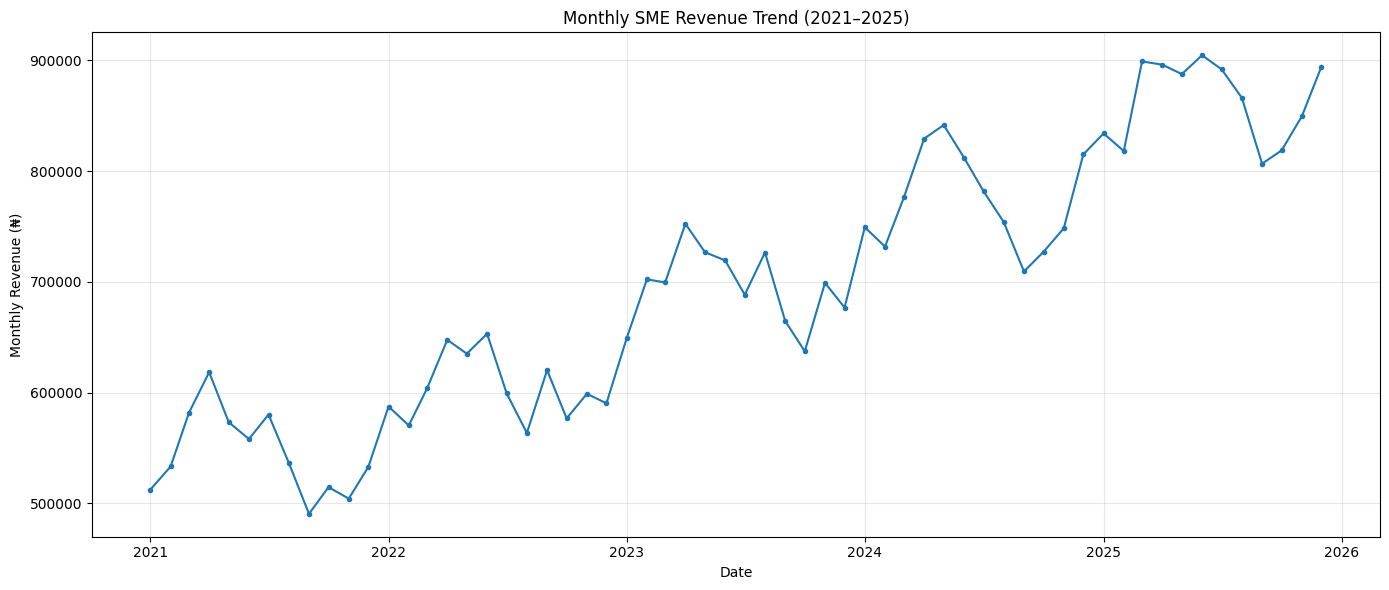

In [27]:
plt.figure(figsize=(14, 6))

plt.plot(
    df.index,
    df["Monthly_Revenue"],
    marker="o",
    markersize=3,
    linewidth=1.5
)

plt.title("Monthly SME Revenue Trend (2021–2025)")
plt.xlabel("Date")
plt.ylabel("Monthly Revenue (₦)")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

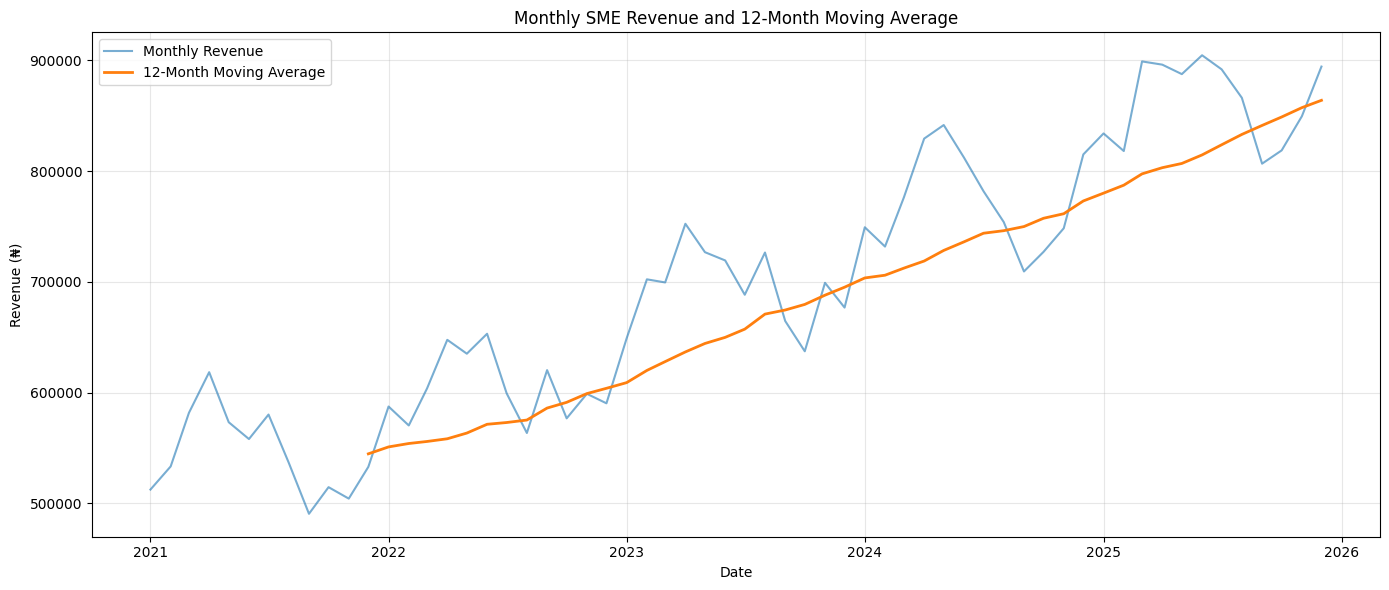

MOVING AVERAGE PREVIEW


,Monthly_Revenue,Moving_Average_12M
Date,,
2021-01-01,"512,417.85",NaN
2021-02-01,"533,323.05",NaN
2021-03-01,"581,713.06",NaN
2021-04-01,"618,414.73",NaN
2021-05-01,"573,226.33",NaN
2021-06-01,"558,044.88",NaN
2021-07-01,"580,158.29",NaN
2021-08-01,"536,643.50",NaN
2021-09-01,"490,538.90",NaN


In [28]:
# Calculate 12-month moving average
df["Moving_Average_12M"] = (
    df["Monthly_Revenue"].rolling(window=12).mean()
)

# Plot original revenue and moving average
plt.figure(figsize=(14, 6))

plt.plot(
    df.index,
    df["Monthly_Revenue"],
    label="Monthly Revenue",
    alpha=0.6
)

plt.plot(
    df.index,
    df["Moving_Average_12M"],
    label="12-Month Moving Average",
    linewidth=2
)

plt.title("Monthly SME Revenue and 12-Month Moving Average")
plt.xlabel("Date")
plt.ylabel("Revenue (₦)")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

print("MOVING AVERAGE PREVIEW")
display(df.head(15))

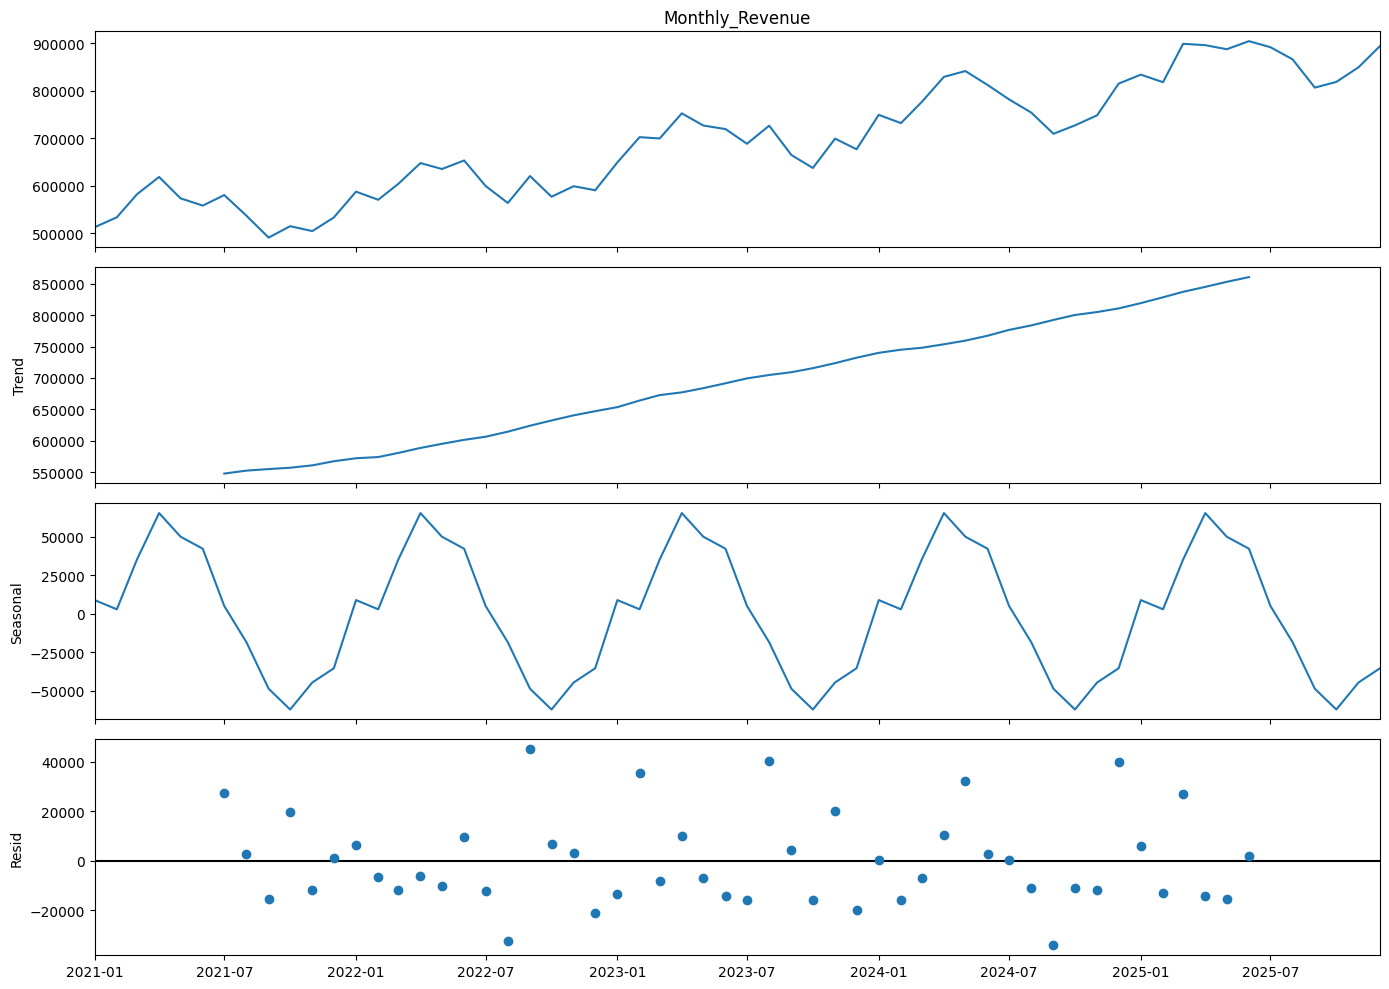

In [29]:
from statsmodels.tsa.seasonal import seasonal_decompose

# Decompose monthly revenue using a 12-month seasonal period
decomposition = seasonal_decompose(
    df["Monthly_Revenue"],
    model="additive",
    period=12
)

# Plot decomposition components
fig = decomposition.plot()
fig.set_size_inches(14, 10)
plt.tight_layout()
plt.show()

In [30]:
# Augmented Dickey-Fuller test
adf_result = adfuller(df["Monthly_Revenue"])

print("AUGMENTED DICKEY-FULLER TEST")
print("=" * 45)

print(f"ADF Statistic: {adf_result[0]:.4f}")
print(f"P-value: {adf_result[1]:.4f}")
print(f"Lags Used: {adf_result[2]}")
print(f"Number of Observations: {adf_result[3]}")

print("\nCritical Values:")
for key, value in adf_result[4].items():
    print(f"{key}: {value:.4f}")

if adf_result[1] < 0.05:
    print("\nConclusion: Reject the null hypothesis.")
    print("The series is stationary at the 5% significance level.")
else:
    print("\nConclusion: Fail to reject the null hypothesis.")
    print("The series is non-stationary at the 5% significance level.")

AUGMENTED DICKEY-FULLER TEST
ADF Statistic: 1.1015
P-value: 0.9952
Lags Used: 10
Number of Observations: 49

Critical Values:
1%: -3.5715
5%: -2.9226
10%: -2.5993

Conclusion: Fail to reject the null hypothesis.
The series is non-stationary at the 5% significance level.


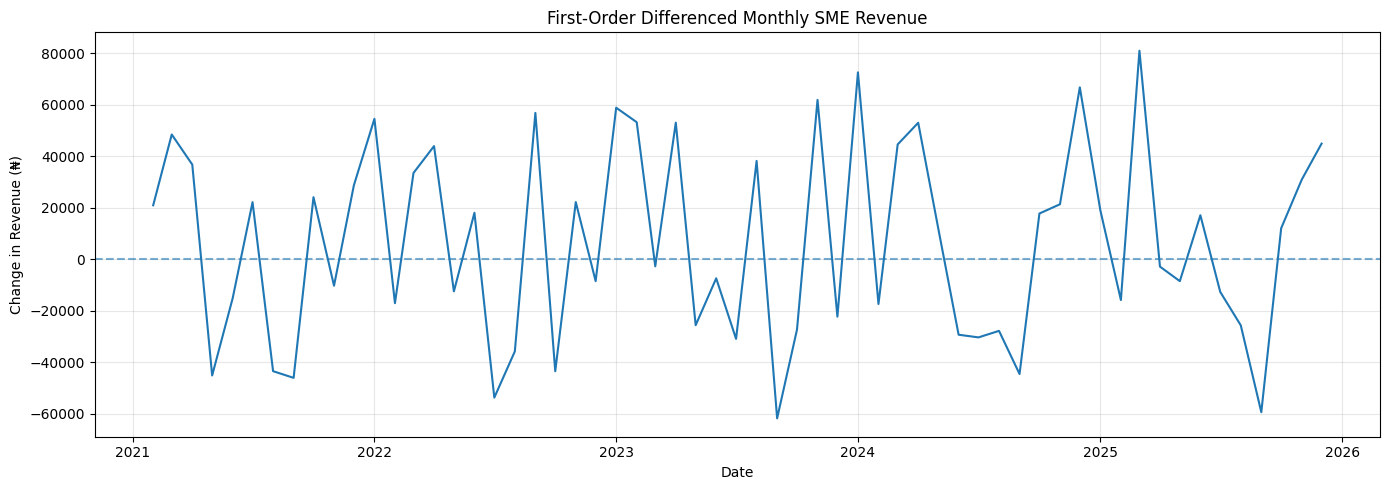

DIFFERENCED SERIES SUMMARY


,Revenue_Differenced
count,59.00
mean,"6,474.08"
std,"37,820.45"
min,"-61,826.25"
25%,"-25,690.28"
50%,"11,991.32"
75%,"37,415.47"
max,"80,919.28"


In [31]:
# Apply first-order differencing
df["Revenue_Differenced"] = df["Monthly_Revenue"].diff()

# Remove the first missing observation
differenced_series = df["Revenue_Differenced"].dropna()

# Plot differenced revenue
plt.figure(figsize=(14, 5))

plt.plot(
    differenced_series.index,
    differenced_series,
    linewidth=1.5
)

plt.axhline(0, linestyle="--", alpha=0.6)

plt.title("First-Order Differenced Monthly SME Revenue")
plt.xlabel("Date")
plt.ylabel("Change in Revenue (₦)")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

print("DIFFERENCED SERIES SUMMARY")
display(differenced_series.describe())

In [32]:
# ADF test on first-order differenced revenue
adf_diff_result = adfuller(differenced_series)

print("ADF TEST AFTER FIRST-ORDER DIFFERENCING")
print("=" * 50)

print(f"ADF Statistic: {adf_diff_result[0]:.4f}")
print(f"P-value: {adf_diff_result[1]:.6f}")
print(f"Lags Used: {adf_diff_result[2]}")
print(f"Number of Observations: {adf_diff_result[3]}")

print("\nCritical Values:")
for key, value in adf_diff_result[4].items():
    print(f"{key}: {value:.4f}")

if adf_diff_result[1] < 0.05:
    print("\nConclusion: Reject the null hypothesis.")
    print("The differenced series is stationary at the 5% significance level.")
else:
    print("\nConclusion: Fail to reject the null hypothesis.")
    print("The differenced series remains non-stationary.")

ADF TEST AFTER FIRST-ORDER DIFFERENCING
ADF Statistic: -7.1857
P-value: 0.000000
Lags Used: 9
Number of Observations: 49

Critical Values:
1%: -3.5715
5%: -2.9226
10%: -2.5993

Conclusion: Reject the null hypothesis.
The differenced series is stationary at the 5% significance level.


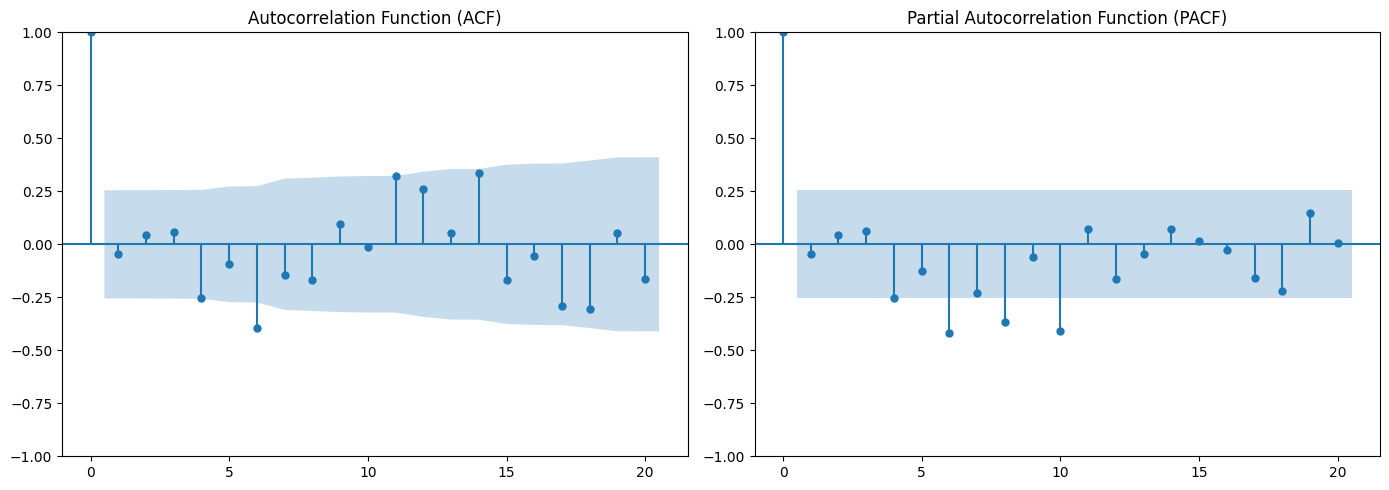

In [33]:
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

plot_acf(
    differenced_series,
    lags=20,
    ax=axes[0]
)

axes[0].set_title("Autocorrelation Function (ACF)")

plot_pacf(
    differenced_series,
    lags=20,
    ax=axes[1],
    method="ywm"
)

axes[1].set_title("Partial Autocorrelation Function (PACF)")

plt.tight_layout()
plt.show()

In [34]:
# Use original revenue series for ARIMA modelling
ts = df["Monthly_Revenue"]

# Chronological train-test split
train = ts.iloc[:-12]
test = ts.iloc[-12:]

print("TRAINING AND TESTING DATA")
print("=" * 40)

print("Training observations:", len(train))
print("Testing observations:", len(test))

print("\nTraining period:")
print(train.index.min(), "to", train.index.max())

print("\nTesting period:")
print(test.index.min(), "to", test.index.max())

TRAINING AND TESTING DATA
Training observations: 48
Testing observations: 12

Training period:
2021-01-01 00:00:00 to 2024-12-01 00:00:00

Testing period:
2025-01-01 00:00:00 to 2025-12-01 00:00:00


In [35]:
# Fit ARIMA(1,1,1) model
arima_model = ARIMA(
    train,
    order=(1, 1, 1)
)

arima_fit = arima_model.fit()

# Display model summary
print(arima_fit.summary())

                               SARIMAX Results                                
Dep. Variable:        Monthly_Revenue   No. Observations:                   48
Model:                 ARIMA(1, 1, 1)   Log Likelihood                -562.851
Date:                Wed, 11 Nov 2026   AIC                           1131.702
Time:                        09:13:37   BIC                           1137.252
Sample:                    01-01-2021   HQIC                          1133.790
                         - 12-01-2024                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1          0.5121      1.291      0.397      0.692      -2.018       3.042
ma.L1         -0.4646      1.405     -0.331      0.741      -3.218       2.288
sigma2      1.487e+09   8.06e-10   1.84e+18      0.0

In [36]:
# Compare candidate ARIMA models
orders = [
    (0, 1, 0),
    (1, 1, 0),
    (0, 1, 1),
    (1, 1, 1)
]

results = []

for order in orders:
    model = ARIMA(train, order=order)
    fitted_model = model.fit()

    results.append({
        "ARIMA_Order": str(order),
        "AIC": fitted_model.aic,
        "BIC": fitted_model.bic
    })

comparison_df = pd.DataFrame(results)

comparison_df = comparison_df.sort_values(
    by="AIC"
).reset_index(drop=True)

print("ARIMA MODEL COMPARISON")
display(comparison_df)

ARIMA MODEL COMPARISON


,ARIMA_Order,AIC,BIC
0,"(0, 1, 0)","1,128.40","1,130.25"
1,"(1, 1, 0)","1,130.30","1,134.00"
2,"(0, 1, 1)","1,130.31","1,134.01"
3,"(1, 1, 1)","1,131.70","1,137.25"


In [37]:
# Fit selected ARIMA(0,1,0) model
best_model = ARIMA(
    train,
    order=(0, 1, 0)
)

best_fit = best_model.fit()

print("SELECTED MODEL: ARIMA(0,1,0)")
print("=" * 45)
print(best_fit.summary())

SELECTED MODEL: ARIMA(0,1,0)
                               SARIMAX Results                                
Dep. Variable:        Monthly_Revenue   No. Observations:                   48
Model:                 ARIMA(0, 1, 0)   Log Likelihood                -563.201
Date:                Wed, 11 Nov 2026   AIC                           1128.402
Time:                        09:13:37   BIC                           1130.252
Sample:                    01-01-2021   HQIC                          1129.098
                         - 12-01-2024                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
sigma2      1.468e+09   4.79e+08      3.064      0.002    5.29e+08    2.41e+09
Ljung-Box (L1) (Q):                   0.27   Jarque-Bera (JB):                 3.38
Prob(Q):          

In [38]:
# Generate 12-month forecast
forecast = best_fit.forecast(steps=12)

# Align forecast dates with test observations
forecast.index = test.index

# Calculate forecast accuracy
mae = mean_absolute_error(test, forecast)
rmse = np.sqrt(mean_squared_error(test, forecast))

print("ARIMA(0,1,0) FORECAST PERFORMANCE")
print("=" * 45)

print(f"Test MAE: ₦{mae:,.2f}")
print(f"Test RMSE: ₦{rmse:,.2f}")

print("\nFORECAST VS ACTUAL REVENUE")
forecast_comparison = pd.DataFrame({
    "Actual_Revenue": test,
    "Forecast_Revenue": forecast
})

display(forecast_comparison)

ARIMA(0,1,0) FORECAST PERFORMANCE
Test MAE: ₦50,229.82
Test RMSE: ₦60,095.65

FORECAST VS ACTUAL REVENUE


,Actual_Revenue,Forecast_Revenue
Date,,
2025-01-01,"834,014.19","815,072.12"
2025-02-01,"818,127.39","815,072.12"
2025-03-01,"899,046.67","815,072.12"
2025-04-01,"896,135.65","815,072.12"
2025-05-01,"887,580.85","815,072.12"
2025-06-01,"904,613.94","815,072.12"
2025-07-01,"891,876.68","815,072.12"
2025-08-01,"866,163.36","815,072.12"
2025-09-01,"806,719.05","815,072.12"


In [39]:
# Fit ARIMA(0,1,0) with a linear trend (drift)
drift_model = ARIMA(
    train,
    order=(0, 1, 0),
    trend="t"
)

drift_fit = drift_model.fit()

# Generate 12-month forecast
drift_forecast = drift_fit.forecast(steps=12)
drift_forecast.index = test.index

# Evaluate forecast
drift_mae = mean_absolute_error(test, drift_forecast)
drift_rmse = np.sqrt(
    mean_squared_error(test, drift_forecast)
)

print("ARIMA(0,1,0) WITH DRIFT")
print("=" * 45)

print(f"Test MAE: ₦{drift_mae:,.2f}")
print(f"Test RMSE: ₦{drift_rmse:,.2f}")

print("\nFORECAST VS ACTUAL REVENUE")

drift_comparison = pd.DataFrame({
    "Actual_Revenue": test,
    "Drift_Forecast": drift_forecast
})

display(drift_comparison)

ARIMA(0,1,0) WITH DRIFT
Test MAE: ₦35,927.56
Test RMSE: ₦42,943.68

FORECAST VS ACTUAL REVENUE


,Actual_Revenue,Drift_Forecast
Date,,
2025-01-01,"834,014.19","821,511.57"
2025-02-01,"818,127.39","827,951.03"
2025-03-01,"899,046.67","834,390.48"
2025-04-01,"896,135.65","840,829.93"
2025-05-01,"887,580.85","847,269.38"
2025-06-01,"904,613.94","853,708.84"
2025-07-01,"891,876.68","860,148.29"
2025-08-01,"866,163.36","866,587.74"
2025-09-01,"806,719.05","873,027.19"


In [40]:
# Seasonal-naive forecast: repeat the previous year's monthly values
seasonal_forecast = train.iloc[-12:].copy()
seasonal_forecast.index = test.index

# Evaluate forecast
seasonal_mae = mean_absolute_error(test, seasonal_forecast)
seasonal_rmse = np.sqrt(
    mean_squared_error(test, seasonal_forecast)
)

print("SEASONAL-NAIVE FORECAST PERFORMANCE")
print("=" * 45)

print(f"Test MAE: ₦{seasonal_mae:,.2f}")
print(f"Test RMSE: ₦{seasonal_rmse:,.2f}")

print("\nFORECAST VS ACTUAL REVENUE")

seasonal_comparison = pd.DataFrame({
    "Actual_Revenue": test,
    "Seasonal_Forecast": seasonal_forecast
})

display(seasonal_comparison)

SEASONAL-NAIVE FORECAST PERFORMANCE
Test MAE: ₦90,868.27
Test RMSE: ₦93,029.25

FORECAST VS ACTUAL REVENUE


,Actual_Revenue,Seasonal_Forecast
Date,,
2025-01-01,"834,014.19","749,289.39"
2025-02-01,"818,127.39","731,855.70"
2025-03-01,"899,046.67","776,383.99"
2025-04-01,"896,135.65","829,328.31"
2025-05-01,"887,580.85","841,609.63"
2025-06-01,"904,613.94","812,250.31"
2025-07-01,"891,876.68","781,854.56"
2025-08-01,"866,163.36","753,997.83"
2025-09-01,"806,719.05","709,380.51"


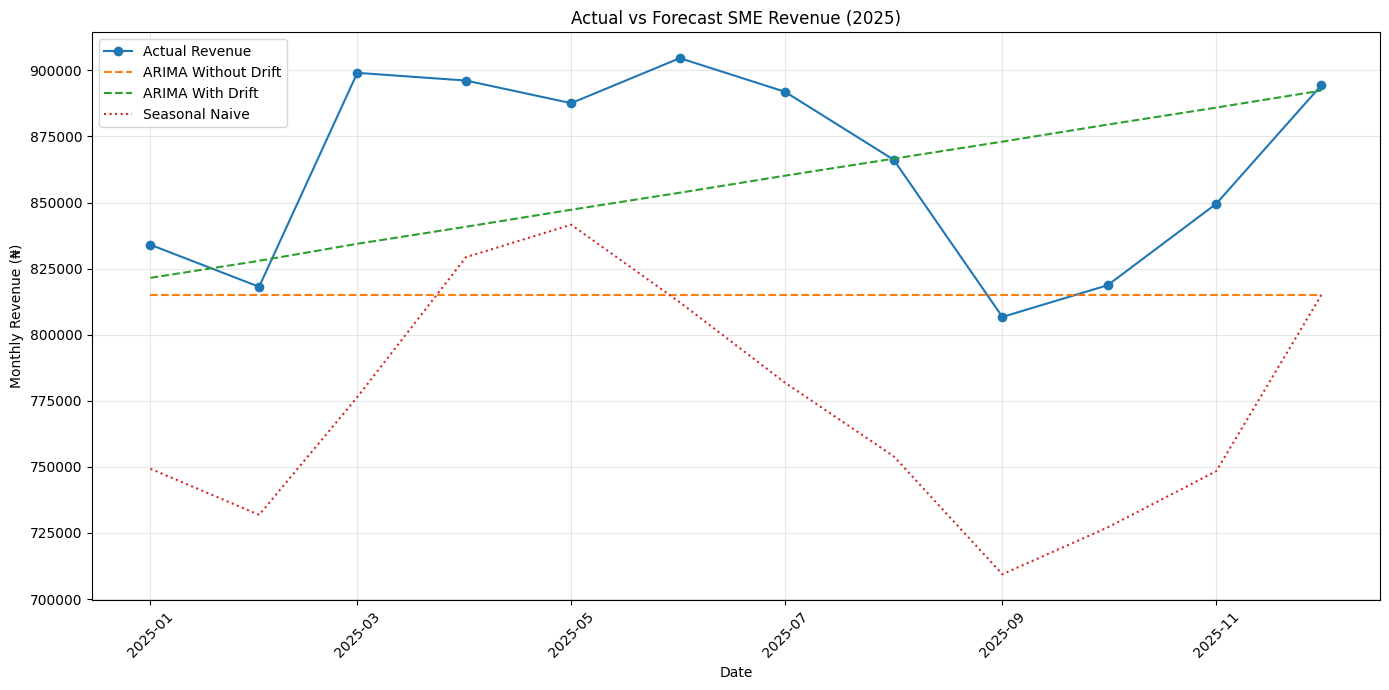

In [41]:
plt.figure(figsize=(14, 7))

plt.plot(test.index, test, label="Actual Revenue", marker="o")
plt.plot(test.index, forecast, label="ARIMA Without Drift", linestyle="--")
plt.plot(test.index, drift_forecast, label="ARIMA With Drift", linestyle="--")
plt.plot(test.index, seasonal_forecast, label="Seasonal Naive", linestyle=":")

plt.title("Actual vs Forecast SME Revenue (2025)")
plt.xlabel("Date")
plt.ylabel("Monthly Revenue (₦)")
plt.legend()
plt.grid(True, alpha=0.3)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [42]:
from statsmodels.tsa.statespace.sarimax import SARIMAX

# Fit SARIMA with annual seasonal differencing
sarima_model = SARIMAX(
    train,
    order=(0, 1, 0),
    seasonal_order=(0, 1, 1, 12),
    trend="n",
    enforce_stationarity=False,
    enforce_invertibility=False
)

sarima_fit = sarima_model.fit(disp=False)

# Generate 12-month forecast
sarima_forecast = sarima_fit.forecast(steps=12)
sarima_forecast.index = test.index

# Evaluate forecast
sarima_mae = mean_absolute_error(test, sarima_forecast)
sarima_rmse = np.sqrt(
    mean_squared_error(test, sarima_forecast)
)

print("SARIMA(0,1,0)(0,1,1,12) PERFORMANCE")
print("=" * 50)
print(f"Test MAE: ₦{sarima_mae:,.2f}")
print(f"Test RMSE: ₦{sarima_rmse:,.2f}")

print("\nFORECAST VS ACTUAL REVENUE")

sarima_comparison = pd.DataFrame({
    "Actual_Revenue": test,
    "SARIMA_Forecast": sarima_forecast
})

display(sarima_comparison)

SARIMA(0,1,0)(0,1,1,12) PERFORMANCE
Test MAE: ₦74,012.45
Test RMSE: ₦76,028.29

FORECAST VS ACTUAL REVENUE


,Actual_Revenue,SARIMA_Forecast
Date,,
2025-01-01,"834,014.19","910,164.35"
2025-02-01,"818,127.39","913,339.61"
2025-03-01,"899,046.67","942,795.19"
2025-04-01,"896,135.65","991,181.96"
2025-05-01,"887,580.85","987,311.17"
2025-06-01,"904,613.94","971,197.75"
2025-07-01,"891,876.68","942,314.99"
2025-08-01,"866,163.36","930,468.83"
2025-09-01,"806,719.05","895,579.46"


In [43]:
model_comparison = pd.DataFrame({
    "Model": [
        "ARIMA(0,1,0) Without Drift",
        "ARIMA(0,1,0) With Drift",
        "Seasonal Naive",
        "SARIMA(0,1,0)(0,1,1,12)"
    ],
    "Test_MAE": [
        mae,
        drift_mae,
        seasonal_mae,
        sarima_mae
    ],
    "Test_RMSE": [
        rmse,
        drift_rmse,
        seasonal_rmse,
        sarima_rmse
    ]
})

model_comparison = model_comparison.sort_values(
    by="Test_RMSE"
).reset_index(drop=True)

print("FINAL FORECAST MODEL COMPARISON")
print("=" * 50)

display(model_comparison)

FINAL FORECAST MODEL COMPARISON


,Model,Test_MAE,Test_RMSE
0,"ARIMA(0,1,0) With Drift","35,927.56","42,943.68"
1,"ARIMA(0,1,0) Without Drift","50,229.82","60,095.65"
2,"SARIMA(0,1,0)(0,1,1,12)","74,012.45","76,028.29"
3,Seasonal Naive,"90,868.27","93,029.25"


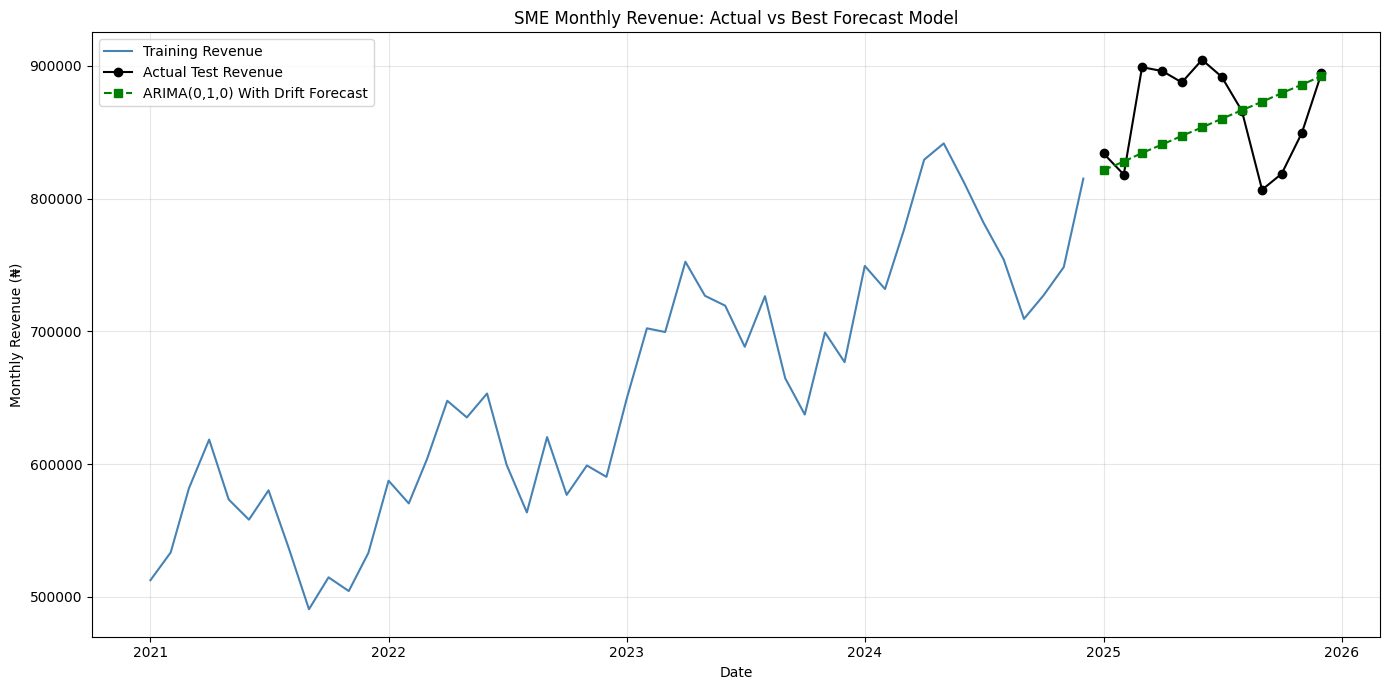

In [44]:
plt.figure(figsize=(14, 7))

plt.plot(
    train.index,
    train,
    label="Training Revenue",
    color="steelblue"
)

plt.plot(
    test.index,
    test,
    label="Actual Test Revenue",
    color="black",
    marker="o"
)

plt.plot(
    drift_forecast.index,
    drift_forecast,
    label="ARIMA(0,1,0) With Drift Forecast",
    color="green",
    linestyle="--",
    marker="s"
)

plt.title("SME Monthly Revenue: Actual vs Best Forecast Model")
plt.xlabel("Date")
plt.ylabel("Monthly Revenue (₦)")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

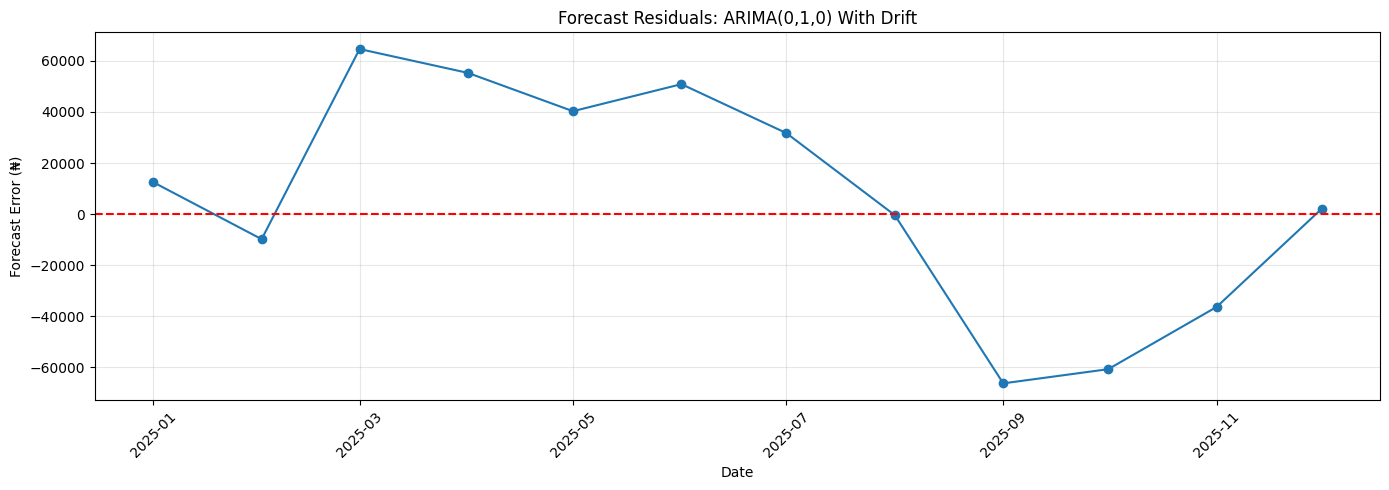

FORECAST RESIDUAL SUMMARY
Mean Residual: ₦6,981.20
Residual Standard Deviation: ₦44,256.55
Maximum Error: ₦64,656.19
Minimum Error: ₦-66,308.14


In [45]:
# Calculate forecast residuals
forecast_residuals = test - drift_forecast

# Plot residuals over time
plt.figure(figsize=(14, 5))

plt.plot(
    forecast_residuals.index,
    forecast_residuals,
    marker="o"
)

plt.axhline(
    y=0,
    color="red",
    linestyle="--"
)

plt.title("Forecast Residuals: ARIMA(0,1,0) With Drift")
plt.xlabel("Date")
plt.ylabel("Forecast Error (₦)")
plt.grid(True, alpha=0.3)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

print("FORECAST RESIDUAL SUMMARY")
print("=" * 40)
print(f"Mean Residual: ₦{forecast_residuals.mean():,.2f}")
print(f"Residual Standard Deviation: ₦{forecast_residuals.std():,.2f}")
print(f"Maximum Error: ₦{forecast_residuals.max():,.2f}")
print(f"Minimum Error: ₦{forecast_residuals.min():,.2f}")

In [46]:
from statsmodels.stats.diagnostic import acorr_ljungbox

# Ljung-Box test on training model residuals
ljung_box_results = acorr_ljungbox(
    best_fit.resid,
    lags=[6, 12],
    return_df=True
)

print("LJUNG-BOX RESIDUAL AUTOCORRELATION TEST")
print("=" * 50)

display(ljung_box_results)

LJUNG-BOX RESIDUAL AUTOCORRELATION TEST


,lb_stat,lb_pvalue
6,1.96,0.92
12,5.26,0.95


## Conclusion

This project applied time series analysis and forecasting techniques to 60 months of synthetic SME revenue data covering January 2021 to December 2025.

The analysis identified an upward revenue trend and a repeating annual seasonal pattern. A 12-month moving average and additive seasonal decomposition were used to examine the underlying trend and seasonal components.

The Augmented Dickey-Fuller test indicated that the original revenue series was non-stationary (p = 0.9952). After first-order differencing, the series became stationary (ADF statistic = -7.1857, p < 0.001), supporting the use of one order of differencing.

Four forecasting approaches were evaluated using a chronological training and test split, with 48 observations for training and 12 observations for testing.

### Forecast Model Comparison

ARIMA(0,1,0) with drift achieved the best performance among the four tested models:

- Test MAE: ₦35,927.56
- Test RMSE: ₦42,943.68

It outperformed ARIMA without drift, seasonal-naive forecasting, and the tested SARIMA specification.

The residual analysis showed a mean forecast error of approximately ₦6,981.20 and a residual standard deviation of approximately ₦44,256.55. The Ljung–Box tests on training residuals did not identify statistically significant autocorrelation at lags 6 and 12.

### Limitations

- The dataset is synthetic and does not represent actual SME financial records.
- The evaluation used a single 12-month holdout period.
- The selected ARIMA model captured the general upward trend but did not fully capture monthly seasonal fluctuations.
- The results should not be interpreted as evidence of real-world forecasting performance.

### Overall Finding

ARIMA(0,1,0) with drift provided the lowest forecasting errors among the candidate models tested on this synthetic dataset. The project demonstrates practical application of time series analysis, stationarity testing, differencing, ARIMA/SARIMA modelling, forecast evaluation, and residual diagnostics using Python.